# HomeVision: Indoor Scene Recognition for Smart Homes
**COMP50056 Advanced Machine Learning | Individual Assignment**  
**Dataset:** MIT Indoor Scenes (Kaggle: `itsahmad/indoor-scenes-cvpr-2019`) | **Framework:** TensorFlow / Keras on Google Colab


---
## 1. Introduction and Objective
### 1.1 Scenario
SmartSense AI is developing **HomeVision**, an indoor camera system that recognises the type of room automatically and adjusts the environment without human input (lighting, HVAC, energy use, occupancy-aware automation). The current prototype struggles with lighting changes, furniture layouts, decor styles, camera angles, clutter and visually similar rooms.

### 1.2 Business problem
Wrong room recognition leads to wrong automation (for example a bedroom lit like a kitchen, or HVAC running in an empty office), which wastes energy and annoys users. The business needs a reliable and fast image classifier.

### 1.3 Objectives
1. Build a classifier for **5 room types**: bathroom, bedroom, kitchen, livingroom, office.
2. Compare a **custom CNN (from scratch)** against **ResNet50 transfer learning**.
3. Evaluate with accuracy, confusion matrices and class-wise metrics, and analyse errors.
4. Discuss limitations, privacy and smart-home implications.

## 2. Environment Setup

In [1]:
import os, shutil, random, time, json, hashlib, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight

warnings.filterwarnings('ignore')
SEED = 42
keras.utils.set_random_seed(SEED)

print('TensorFlow:', tf.__version__)
print('GPU available:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ---- Global configuration ----
CLASSES     = ['bathroom', 'bedroom', 'kitchen', 'livingroom', 'office']
NUM_CLASSES = len(CLASSES)
IMG_SIZE    = (224, 224)   # ResNet50 native size; reused for the CNN for a fair comparison
BATCH       = 32
AUTOTUNE    = tf.data.AUTOTUNE
RAW_DIR     = '/content/raw'
IMG_EXT     = ('.jpg', '.jpeg', '.png', '.bmp')

## 3. Download Dataset from Kaggle

In [3]:
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print('Kaggle credentials loaded from Colab Secrets.')
except Exception as e:
    from google.colab import files
    print('Secrets not found. Please upload kaggle.json')
    files.upload()
    os.makedirs('/root/.kaggle', exist_ok=True)
    shutil.move('kaggle.json', '/root/.kaggle/kaggle.json')
    os.chmod('/root/.kaggle/kaggle.json', 0o600)

Secrets not found. Please upload kaggle.json


Saving kaggle.json to kaggle.json


In [4]:
!kaggle datasets download -d itsahmad/indoor-scenes-cvpr-2019 -p /content/raw --unzip -q
!ls /content/raw

Dataset URL: https://www.kaggle.com/datasets/itsahmad/indoor-scenes-cvpr-2019
License(s): DbCL-1.0
indoorCVPR_09  indoorCVPR_09annotations  TestImages.txt  TrainImages.txt


## 4. Dataset Exploration

### 4.1 Folder structure

In [5]:
lines = 0
for root, dirs, files in os.walk(RAW_DIR):
    depth = root[len(RAW_DIR):].count(os.sep)
    if depth <= 2 and lines < 40:
        print('  ' * depth + os.path.basename(root) + f'/  ({len(files)} files, {len(dirs)} sub-folders)')
        lines += 1
print('\n(output limited to 40 lines)')

raw/  (2 files, 2 sub-folders)
  indoorCVPR_09annotations/  (0 files, 1 sub-folders)
    Annotations/  (0 files, 67 sub-folders)
  indoorCVPR_09/  (0 files, 1 sub-folders)
    Images/  (0 files, 67 sub-folders)

(output limited to 40 lines)


### 4.2 Selected classes and 4.3 Image counts
The archive holds all 67 MIT scene categories. We locate the five chosen class folders anywhere in the archive and pool their images.

In [6]:
found = {c: {} for c in CLASSES}
for root, dirs, files in os.walk(RAW_DIR):
    name = os.path.basename(root).lower()
    if name in CLASSES:
        for f in files:
            if f.lower().endswith(IMG_EXT):
                found[name].setdefault(f, os.path.join(root, f))   # de-duplicate by file name

missing = [c for c in CLASSES if len(found[c]) == 0]
assert not missing, f'Class folders not found: {missing}. Inspect /content/raw structure.'

df = pd.DataFrame([(p, c) for c in CLASSES for p in found[c].values()], columns=['path', 'label'])
df['label_id'] = df['label'].map({c: i for i, c in enumerate(CLASSES)})
print('Selected classes:', CLASSES)
print('Total images found:', len(df))
print(df['label'].value_counts().reindex(CLASSES))

Selected classes: ['bathroom', 'bedroom', 'kitchen', 'livingroom', 'office']
Total images found: 2408
label
bathroom      197
bedroom       662
kitchen       734
livingroom    706
office        109
Name: count, dtype: int64


### 4.4 Sample images

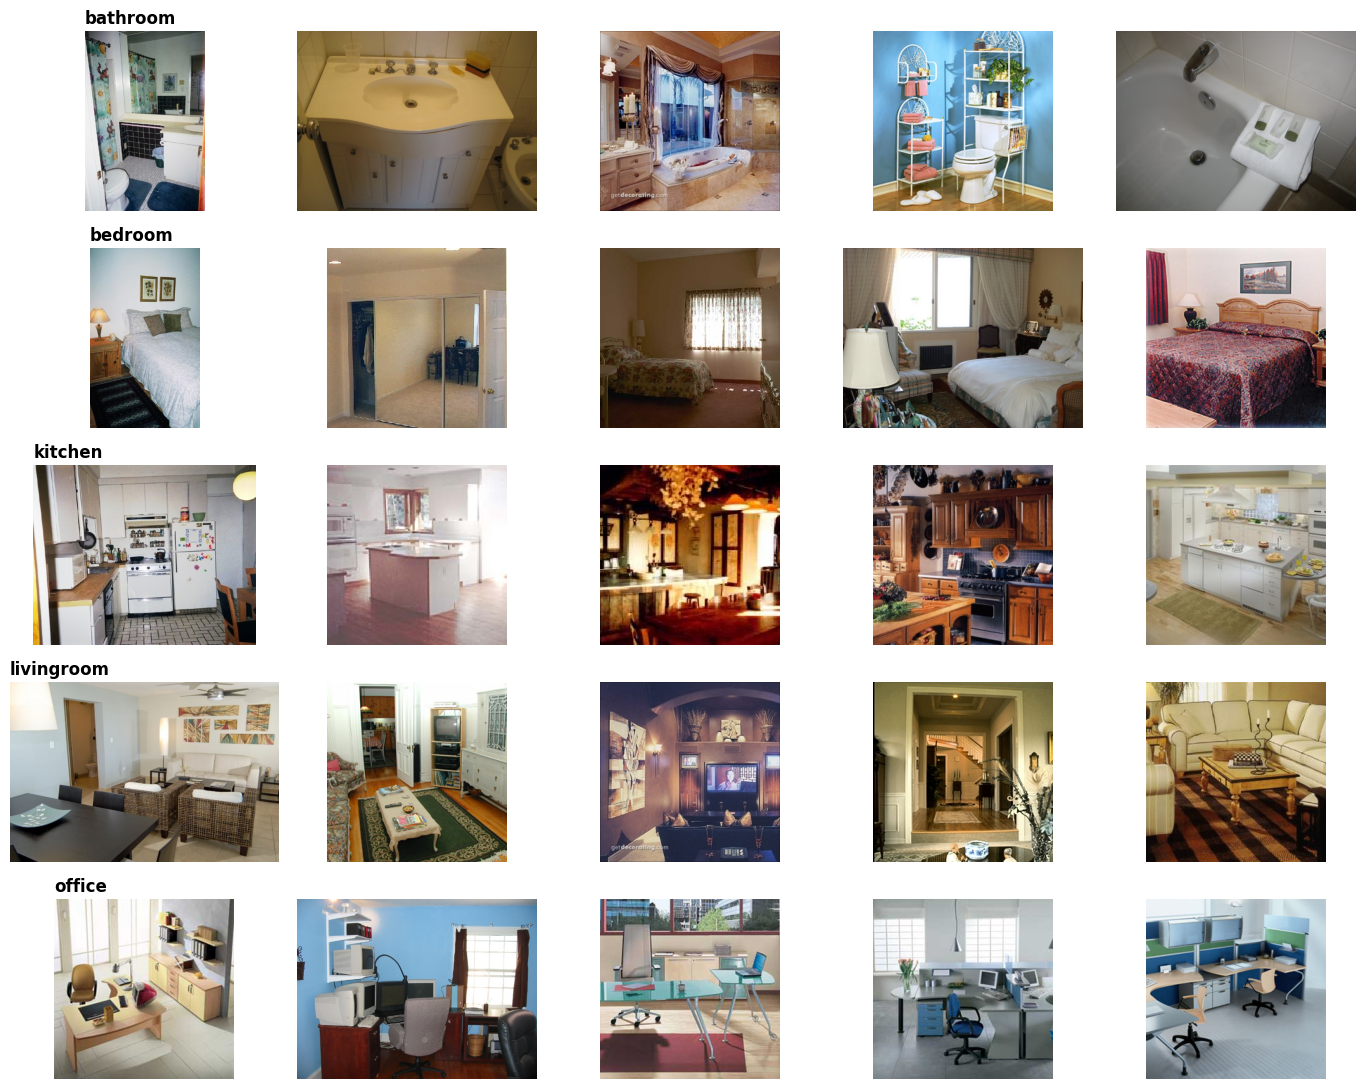

In [7]:
fig, axes = plt.subplots(NUM_CLASSES, 5, figsize=(14, 11))
for r, c in enumerate(CLASSES):
    samples = df[df.label == c].sample(5, random_state=SEED)['path'].tolist()
    for k, p in enumerate(samples):
        axes[r, k].imshow(Image.open(p).convert('RGB'))
        axes[r, k].axis('off')
        if k == 0:
            axes[r, k].set_title(c, loc='left', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

### 4.5 Class distribution

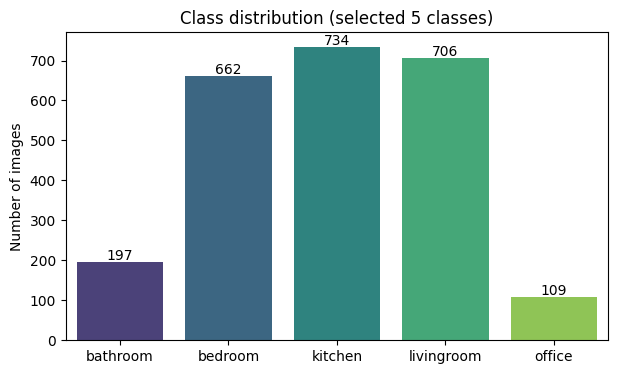

Imbalance ratio (max/min): 6.73
The dataset is imbalanced, so class weights are used in training and per-class F1 is reported.


In [8]:
counts = df['label'].value_counts().reindex(CLASSES)
plt.figure(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, palette='viridis')
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, str(v), ha='center')
plt.title('Class distribution (selected 5 classes)')
plt.ylabel('Number of images'); plt.xlabel('')
plt.show()
print('Imbalance ratio (max/min): %.2f' % (counts.max() / counts.min()))
print('The dataset is imbalanced, so class weights are used in training and per-class F1 is reported.')

## 5. Data Cleaning / Validation
Checks performed: (1) every file opens and decodes, (2) images are not tiny, (3) exact duplicate files are removed (duplicates could leak between train and test and inflate accuracy), (4) image-size statistics.

In [9]:
valid_rows, corrupt, tiny = [], [], []
for p, c in zip(df['path'], df['label']):
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            w, h = im.size
        if min(w, h) < 64:
            tiny.append(p); continue
        valid_rows.append((p, c, w, h))
    except Exception:
        corrupt.append(p)

clean = pd.DataFrame(valid_rows, columns=['path', 'label', 'width', 'height'])
print(f'Corrupt/unreadable removed: {len(corrupt)} | too small removed: {len(tiny)}')

# Exact-duplicate detection via MD5 hash
def md5(p):
    with open(p, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()
clean['hash'] = clean['path'].apply(md5)
n_dup = clean.duplicated('hash').sum()
clean = clean.drop_duplicates('hash').reset_index(drop=True)
print(f'Exact duplicates removed: {n_dup}')

clean['label_id'] = clean['label'].map({c: i for i, c in enumerate(CLASSES)})
df = clean[['path', 'label', 'label_id']].copy()
print(f'Clean dataset size: {len(df)}')
print(clean[['width', 'height']].describe().loc[['min', 'mean', 'max']].round(0))
print('Image sizes vary widely, so all images are resized to', IMG_SIZE)
print(df['label'].value_counts().reindex(CLASSES))

Corrupt/unreadable removed: 0 | too small removed: 0
Exact duplicates removed: 20
Clean dataset size: 2388
       width  height
min    200.0   171.0
mean   467.0   418.0
max   3264.0  2592.0
Image sizes vary widely, so all images are resized to (224, 224)
label
bathroom      197
bedroom       653
kitchen       730
livingroom    699
office        109
Name: count, dtype: int64


## 6. Train / Validation / Test Split
Stratified **70% / 15% / 15%** so every split keeps the class proportions. The validation set is used for tuning and early stopping. The test set is used only for final evaluation.

In [10]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df['label_id'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df['label_id'], random_state=SEED)

print(f'Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}')
print(pd.DataFrame({'train': train_df.label.value_counts(),
                    'val': val_df.label.value_counts(),
                    'test': test_df.label.value_counts()}).reindex(CLASSES))

y_train = train_df['label_id'].values.astype('int32')
y_val   = val_df['label_id'].values.astype('int32')
y_test  = test_df['label_id'].values.astype('int32')
test_paths = test_df['path'].tolist()

# Class weights (inverse frequency) to counter the imbalance
cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i: float(w) for i, w in enumerate(cw)}
print('Class weights:', {CLASSES[i]: round(w, 2) for i, w in class_weights.items()})

Train: 1671 | Val: 358 | Test: 359
            train  val  test
label                       
bathroom      138   29    30
bedroom       457   98    98
kitchen       511  109   110
livingroom    489  105   105
office         76   17    16
Class weights: {'bathroom': 2.42, 'bedroom': 0.73, 'kitchen': 0.65, 'livingroom': 0.68, 'office': 4.4}


## 7. Image Preprocessing
* **Resize:** 224x224 for both models.
* **Normalisation:** done inside each model so one dataset feeds both. The CNN uses `1/255` scaling. ResNet50 uses its own `preprocess_input` (BGR conversion plus ImageNet mean subtraction), which the pretrained weights require.
* **Augmentation:** flip, rotation, zoom, contrast and brightness, chosen to mimic the scenario's problems (camera angles, lighting, clutter). It is a model layer, so it is active in training only, never in validation or test.

### 7.1 Resize and tf.data pipeline

In [11]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(tf.clip_by_value(img, 0, 255), tf.uint8)   # uint8 keeps the cache small
    return img, label

def make_ds(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), labels))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE).cache()
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)

train_ds = make_ds(train_df['path'], y_train, True)
val_ds   = make_ds(val_df['path'],   y_val,   False)
test_ds  = make_ds(test_df['path'],  y_test,  False)   # not shuffled: order matches y_test
print('tf.data pipelines ready.')

tf.data pipelines ready.


### 7.2 Normalisation
Applied inside the models: `Rescaling(1/255)` for the CNN (Section 8) and `preprocess_input` for ResNet50 (Section 10).

### 7.3 Augmentation

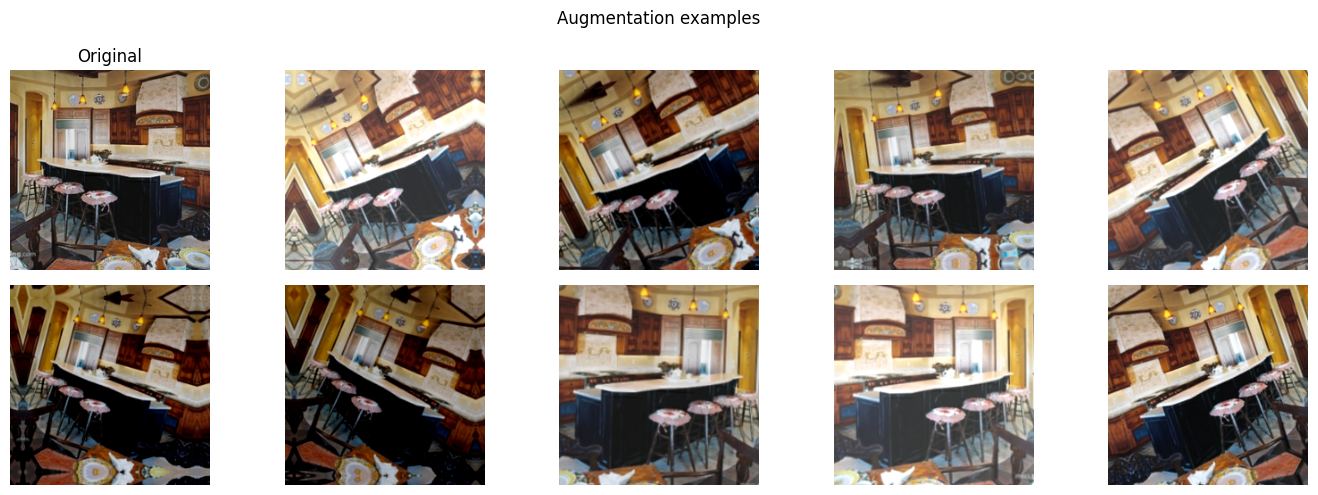

In [12]:
def build_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.2),
        layers.RandomBrightness(0.2, value_range=(0, 255)),
    ], name='augmentation')

img_batch, _ = next(iter(train_ds))
aug = build_augmentation()
plt.figure(figsize=(14, 5))
plt.subplot(2, 5, 1); plt.imshow(img_batch[0].numpy().astype('uint8')); plt.title('Original'); plt.axis('off')
for i in range(2, 11):
    out = aug(tf.expand_dims(tf.cast(img_batch[0], tf.float32), 0), training=True)[0]
    plt.subplot(2, 5, i); plt.imshow(np.clip(out.numpy(), 0, 255).astype('uint8')); plt.axis('off')
plt.suptitle('Augmentation examples'); plt.tight_layout(); plt.show()

## 8. Model 1: Custom CNN

### 8.1 Architecture and rationale
* Four convolutional blocks with doubling filters (32, 64, 128, 256): early layers learn edges and textures, deeper layers learn object parts such as sinks, beds and desks.
* Two 3x3 convolutions per block give a larger receptive field with fewer parameters than one large kernel.
* Batch Normalisation stabilises and speeds up training; ReLU adds non-linearity.
* MaxPooling reduces spatial size; block Dropout and head Dropout limit overfitting on a small dataset.
* **Global Average Pooling** replaces Flatten, which cuts parameters and overfitting.
* Softmax over 5 classes, sparse categorical cross-entropy, Adam optimiser.

In [13]:
def conv_block(x, filters, drop=0.2):
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding='same', use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)
    return layers.Dropout(drop)(x)

def build_cnn(lr=1e-3, dropout=0.5):
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Rescaling(1. / 255)(x)
    for f in (32, 64, 128, 256):
        x = conv_block(x, f)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu', kernel_regularizer=keras.regularizers.l2(1e-4))(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)
    model = keras.Model(inputs, outputs, name='custom_cnn')
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

build_cnn().summary()

Model: "custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 224, 224, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 224, 224, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 112, 112, 64)   │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 112, 112, 64)   │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 56, 56, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 1,208,677 (4.61 MB)

 Trainable params: 1,206,757 (4.60 MB)

 Non-trainable params: 1,920 (7.50 KB)

### 8.2 Callbacks and hyperparameter tuning
* **EarlyStopping** (patience 8, restores best weights) stops training when validation loss stops improving.
* **ReduceLROnPlateau** halves the learning rate when progress stalls.
* A small grid search over learning rate and dropout uses **validation accuracy only**. The best configuration is used for final training.

In [14]:
def get_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ]

def plot_history(history, title, boundary=None):
    h = history if isinstance(history, dict) else history.history
    ep = range(1, len(h['accuracy']) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    ax[0].plot(ep, h['accuracy'], label='train'); ax[0].plot(ep, h['val_accuracy'], label='validation')
    ax[0].set_title(title + ': accuracy'); ax[0].set_xlabel('epoch')
    ax[1].plot(ep, h['loss'], label='train'); ax[1].plot(ep, h['val_loss'], label='validation')
    ax[1].set_title(title + ': loss'); ax[1].set_xlabel('epoch')
    if boundary:
        for a in ax:
            a.axvline(boundary + 0.5, color='red', linestyle='--', label='fine-tuning starts')
    for a in ax: a.legend()
    plt.tight_layout(); plt.show()

def tune(build_fn, grid, epochs=6):
    rows = []
    for cfg in grid:
        keras.backend.clear_session()
        keras.utils.set_random_seed(SEED)
        m = build_fn(**cfg)
        h = m.fit(train_ds, validation_data=val_ds, epochs=epochs,
                  class_weight=class_weights, verbose=0)
        rows.append({**cfg, 'best_val_acc': max(h.history['val_accuracy']),
                     'final_val_loss': h.history['val_loss'][-1]})
        print(cfg, '-> best val acc: %.4f' % rows[-1]['best_val_acc'])
    return pd.DataFrame(rows).sort_values('best_val_acc', ascending=False).reset_index(drop=True)

grid = [{'lr': lr, 'dropout': d} for lr in (1e-3, 3e-4) for d in (0.3, 0.5)]
cnn_tuning = tune(build_cnn, grid, epochs=8)
display(cnn_tuning)
best_cnn_cfg = cnn_tuning.iloc[0][['lr', 'dropout']].to_dict()
print('Best CNN config:', best_cnn_cfg)

{'lr': 0.001, 'dropout': 0.3} -> best val acc: 0.2011
{'lr': 0.001, 'dropout': 0.5} -> best val acc: 0.1173
{'lr': 0.0003, 'dropout': 0.3} -> best val acc: 0.0838
{'lr': 0.0003, 'dropout': 0.5} -> best val acc: 0.1536


,lr,dropout,best_val_acc,final_val_loss
0,0.0010,0.3,0.201117,1.768220
1,0.0003,0.5,0.153631,1.947726
2,0.0010,0.5,0.117318,2.246117
3,0.0003,0.3,0.083799,3.136843


Best CNN config: {'lr': 0.001, 'dropout': 0.3}


### 8.3 Training and 8.4 Results

In [15]:
keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
cnn = build_cnn(**best_cnn_cfg)
t0 = time.time()
hist_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=60,
                   class_weight=class_weights, callbacks=get_callbacks(), verbose=2)
cnn_train_time = time.time() - t0
print('CNN training time: %.1f s' % cnn_train_time)
print('Best validation accuracy: %.4f' % max(hist_cnn.history['val_accuracy']))

Epoch 1/60
53/53 - 23s - 436ms/step - accuracy: 0.2406 - loss: 1.7061 - val_accuracy: 0.0810 - val_loss: 1.8151 - learning_rate: 0.0010
Epoch 2/60
53/53 - 18s - 340ms/step - accuracy: 0.2196 - loss: 1.6436 - val_accuracy: 0.0810 - val_loss: 2.9527 - learning_rate: 0.0010
Epoch 3/60
53/53 - 18s - 335ms/step - accuracy: 0.2214 - loss: 1.5415 - val_accuracy: 0.0810 - val_loss: 4.0858 - learning_rate: 0.0010
Epoch 4/60

Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
53/53 - 18s - 334ms/step - accuracy: 0.2250 - loss: 1.5289 - val_accuracy: 0.0810 - val_loss: 2.7707 - learning_rate: 0.0010
Epoch 5/60
53/53 - 18s - 333ms/step - accuracy: 0.2394 - loss: 1.4808 - val_accuracy: 0.0810 - val_loss: 3.7857 - learning_rate: 5.0000e-04
Epoch 6/60
53/53 - 18s - 335ms/step - accuracy: 0.2729 - loss: 1.4914 - val_accuracy: 0.0810 - val_loss: 2.8809 - learning_rate: 5.0000e-04
Epoch 7/60

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
53/53 - 18s

## 9. Model 1 Evaluation

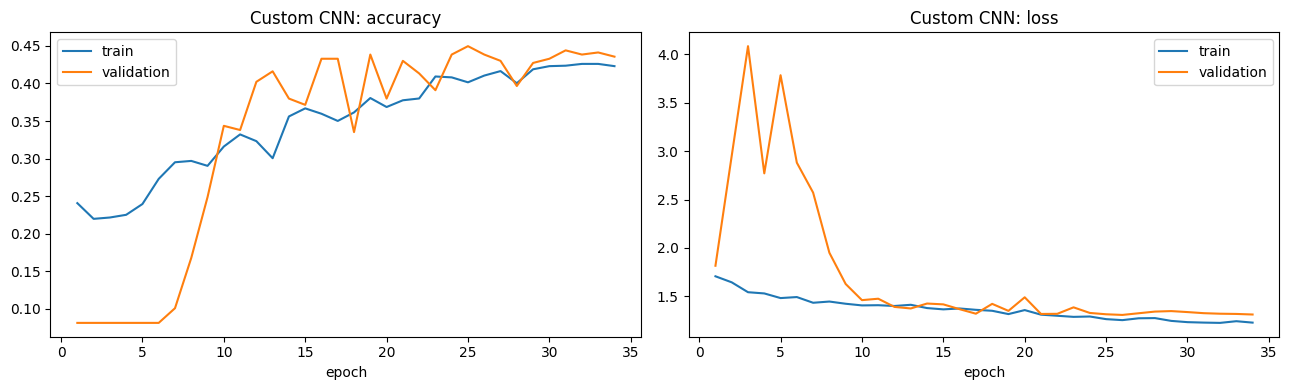

===== Custom CNN =====
Test accuracy: 0.4930 | Macro-F1: 0.4542 | Inference: 2.05 ms/image
              precision    recall  f1-score   support

    bathroom     0.4146    0.5667    0.4789        30
     bedroom     0.5851    0.5612    0.5729        98
     kitchen     0.5303    0.3182    0.3977       110
  livingroom     0.4885    0.6095    0.5424       105
      office     0.2222    0.3750    0.2791        16

    accuracy                         0.4930       359
   macro avg     0.4482    0.4861    0.4542       359
weighted avg     0.5097    0.4930    0.4893       359



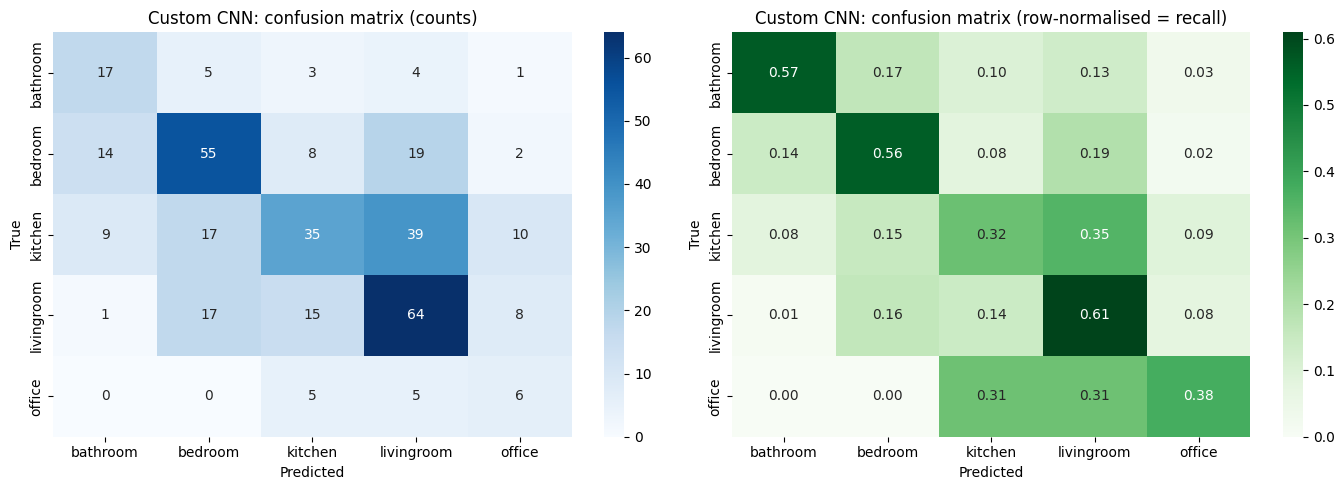

In [16]:
def predict_probs(model):
    model.predict(test_ds, verbose=0)                    # warm-up (fills cache)
    t0 = time.time()
    probs = model.predict(test_ds, verbose=0)
    ms_per_img = (time.time() - t0) / len(y_test) * 1000
    return probs, ms_per_img

def evaluate_model(model, name):
    probs, ms = predict_probs(model)
    y_pred = probs.argmax(1)
    acc = accuracy_score(y_test, y_pred)
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, average=None, labels=range(NUM_CLASSES))
    print(f'===== {name} =====')
    print('Test accuracy: %.4f | Macro-F1: %.4f | Inference: %.2f ms/image' % (acc, f.mean(), ms))
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))
    cm = confusion_matrix(y_test, y_pred)
    cmn = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[0])
    ax[0].set_title(name + ': confusion matrix (counts)')
    sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Greens', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
    ax[1].set_title(name + ': confusion matrix (row-normalised = recall)')
    for a in ax: a.set_xlabel('Predicted'); a.set_ylabel('True')
    plt.tight_layout(); plt.show()
    return {'name': name, 'accuracy': acc, 'macro_f1': f.mean(), 'f1': f, 'precision': p, 'recall': r,
            'ms_per_image': ms, 'params': model.count_params(), 'probs': probs, 'y_pred': y_pred}

# 9.1 accuracy/loss plots, 9.2 test accuracy + confusion matrix + classification report
plot_history(hist_cnn, 'Custom CNN')
res_cnn = evaluate_model(cnn, 'Custom CNN')

## 10. Model 2: ResNet50 Transfer Learning

### 10.1 Pretrained backbone
ResNet50 pretrained on ImageNet (about 1.2M images) already encodes general visual features such as edges, textures and object parts. With only a few thousand training images, transfer learning normally beats training from scratch. Its residual (skip) connections let gradients flow through 50 layers, avoiding vanishing gradients. We remove the original classifier and add a new head: Global Average Pooling, Dropout, Softmax(5).

In [17]:
def build_resnet(lr=1e-3, dropout=0.3):
    base = ResNet50(include_top=False, weights='imagenet', input_shape=(*IMG_SIZE, 3))
    base.trainable = False                      # Stage 1: frozen backbone
    inputs = keras.Input(shape=(*IMG_SIZE, 3))
    x = build_augmentation()(inputs)
    x = layers.Lambda(lambda t: preprocess_input(tf.cast(t, tf.float32)), name='resnet_preprocess')(x)
    x = base(x, training=False)                 # keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name='predictions')(x)
    model = keras.Model(inputs, outputs, name='resnet50_transfer')
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def get_base(model):
    # Return the ResNet50 backbone (not the augmentation Sequential, which is also a keras.Model)
    for l in model.layers:
        if isinstance(l, keras.Model) and l.name.startswith('resnet50'):
            return l
    raise ValueError('ResNet50 backbone not found')

build_resnet().summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet_preprocess (Lambda)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

### 10.2 Frozen training stage
Only the new head is trained (higher learning rate). First a small tuning grid on the validation set, then full training of the head.

In [18]:
resnet_tuning = tune(build_resnet, grid, epochs=5)
display(resnet_tuning)
best_resnet_cfg = resnet_tuning.iloc[0][['lr', 'dropout']].to_dict()
print('Best ResNet50 head config:', best_resnet_cfg)

{'lr': 0.001, 'dropout': 0.3} -> best val acc: 0.8408
{'lr': 0.001, 'dropout': 0.5} -> best val acc: 0.8101
{'lr': 0.0003, 'dropout': 0.3} -> best val acc: 0.7709
{'lr': 0.0003, 'dropout': 0.5} -> best val acc: 0.7793


,lr,dropout,best_val_acc,final_val_loss
0,0.0010,0.3,0.840782,0.547383
1,0.0010,0.5,0.810056,0.637651
2,0.0003,0.5,0.779330,0.616675
3,0.0003,0.3,0.770950,0.633480


Best ResNet50 head config: {'lr': 0.001, 'dropout': 0.3}


Epoch 1/25
53/53 - 19s - 357ms/step - accuracy: 0.4895 - loss: 1.2959 - val_accuracy: 0.7765 - val_loss: 0.6513 - learning_rate: 0.0010
Epoch 2/25
53/53 - 9s - 169ms/step - accuracy: 0.6571 - loss: 0.8636 - val_accuracy: 0.7402 - val_loss: 0.6949 - learning_rate: 0.0010
Epoch 3/25
53/53 - 9s - 172ms/step - accuracy: 0.7044 - loss: 0.7455 - val_accuracy: 0.7598 - val_loss: 0.6586 - learning_rate: 0.0010
Epoch 4/25
53/53 - 9s - 177ms/step - accuracy: 0.7056 - loss: 0.7266 - val_accuracy: 0.7654 - val_loss: 0.5993 - learning_rate: 0.0010
Epoch 5/25
53/53 - 9s - 174ms/step - accuracy: 0.7534 - loss: 0.5961 - val_accuracy: 0.8128 - val_loss: 0.5016 - learning_rate: 0.0010
Epoch 6/25
53/53 - 9s - 171ms/step - accuracy: 0.7504 - loss: 0.5768 - val_accuracy: 0.8128 - val_loss: 0.5352 - learning_rate: 0.0010
Epoch 7/25
53/53 - 9s - 172ms/step - accuracy: 0.7582 - loss: 0.5610 - val_accuracy: 0.8240 - val_loss: 0.4930 - learning_rate: 0.0010
Epoch 8/25
53/53 - 9s - 170ms/step - accuracy: 0.7768 

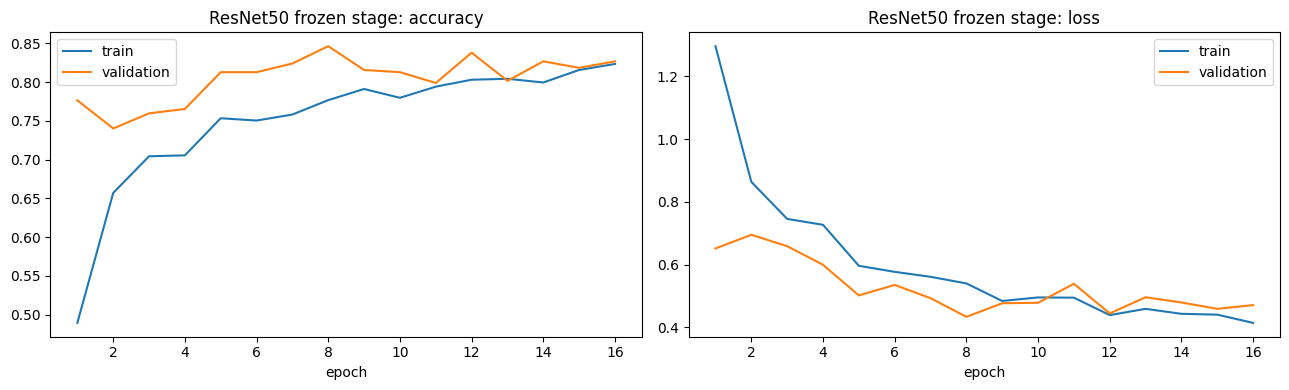

In [19]:
keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
resnet = build_resnet(**best_resnet_cfg)
t0 = time.time()
hist_p1 = resnet.fit(train_ds, validation_data=val_ds, epochs=25,
                     class_weight=class_weights, callbacks=get_callbacks(), verbose=2)
print('Frozen stage done. Best val acc: %.4f' % max(hist_p1.history['val_accuracy']))
plot_history(hist_p1, 'ResNet50 frozen stage')

## 11. ResNet50 Fine-Tuning
* **Unfreeze selected layers:** the last 30 layers of the backbone (the most task-specific, high-level features).
* **Low learning rate (1e-5):** small updates adapt features without destroying pretrained knowledge.
* **BatchNorm stays frozen:** recommended for fine-tuning with small batches.
* **Retrain** with the same callbacks.

In [20]:
def unfreeze_for_finetuning(model, n_layers=30, lr=1e-5):
    base = get_base(model)
    base.trainable = True
    for l in base.layers[:-n_layers]:
        l.trainable = False
    for l in base.layers:
        if isinstance(l, layers.BatchNormalization):
            l.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    n_train = sum(int(np.prod(w.shape)) for w in model.trainable_weights)
    print(f'Backbone: {base.name} | unfrozen layers: {sum(l.trainable for l in base.layers)} | trainable params: {n_train:,}')

unfreeze_for_finetuning(resnet, n_layers=30, lr=1e-5)
hist_p2 = resnet.fit(train_ds, validation_data=val_ds, epochs=25,
                     class_weight=class_weights, callbacks=get_callbacks(), verbose=2)
resnet_train_time = time.time() - t0
print('ResNet50 total training time (both stages): %.1f s' % resnet_train_time)
print('Best validation accuracy after fine-tuning: %.4f' % max(hist_p2.history['val_accuracy']))

Backbone: resnet50 | unfrozen layers: 21 | trainable params: 14,438,917
Epoch 1/25
53/53 - 23s - 442ms/step - accuracy: 0.7917 - loss: 0.4989 - val_accuracy: 0.8156 - val_loss: 0.4898 - learning_rate: 1.0000e-05
Epoch 2/25
53/53 - 11s - 209ms/step - accuracy: 0.8133 - loss: 0.4207 - val_accuracy: 0.8380 - val_loss: 0.4504 - learning_rate: 1.0000e-05
Epoch 3/25
53/53 - 11s - 212ms/step - accuracy: 0.8402 - loss: 0.4050 - val_accuracy: 0.8101 - val_loss: 0.5436 - learning_rate: 1.0000e-05
Epoch 4/25
53/53 - 11s - 213ms/step - accuracy: 0.8247 - loss: 0.3899 - val_accuracy: 0.8408 - val_loss: 0.4703 - learning_rate: 1.0000e-05
Epoch 5/25
53/53 - 11s - 211ms/step - accuracy: 0.8408 - loss: 0.3459 - val_accuracy: 0.8464 - val_loss: 0.4500 - learning_rate: 1.0000e-05
Epoch 6/25
53/53 - 11s - 206ms/step - accuracy: 0.8659 - loss: 0.3072 - val_accuracy: 0.8352 - val_loss: 0.4442 - learning_rate: 1.0000e-05
Epoch 7/25
53/53 - 11s - 205ms/step - accuracy: 0.8713 - loss: 0.3033 - val_accuracy: 0.

## 12. Model 2 Evaluation

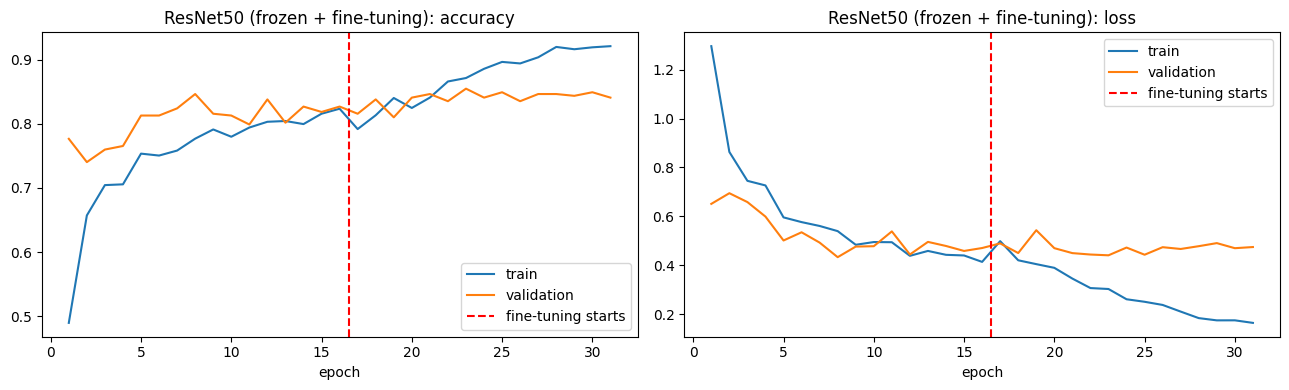

===== ResNet50 (fine-tuned) =====
Test accuracy: 0.8496 | Macro-F1: 0.8015 | Inference: 4.17 ms/image
              precision    recall  f1-score   support

    bathroom     0.8621    0.8333    0.8475        30
     bedroom     0.7965    0.9184    0.8531        98
     kitchen     0.9444    0.9273    0.9358       110
  livingroom     0.8667    0.7429    0.8000       105
      office     0.5263    0.6250    0.5714        16

    accuracy                         0.8496       359
   macro avg     0.7992    0.8094    0.8015       359
weighted avg     0.8558    0.8496    0.8499       359



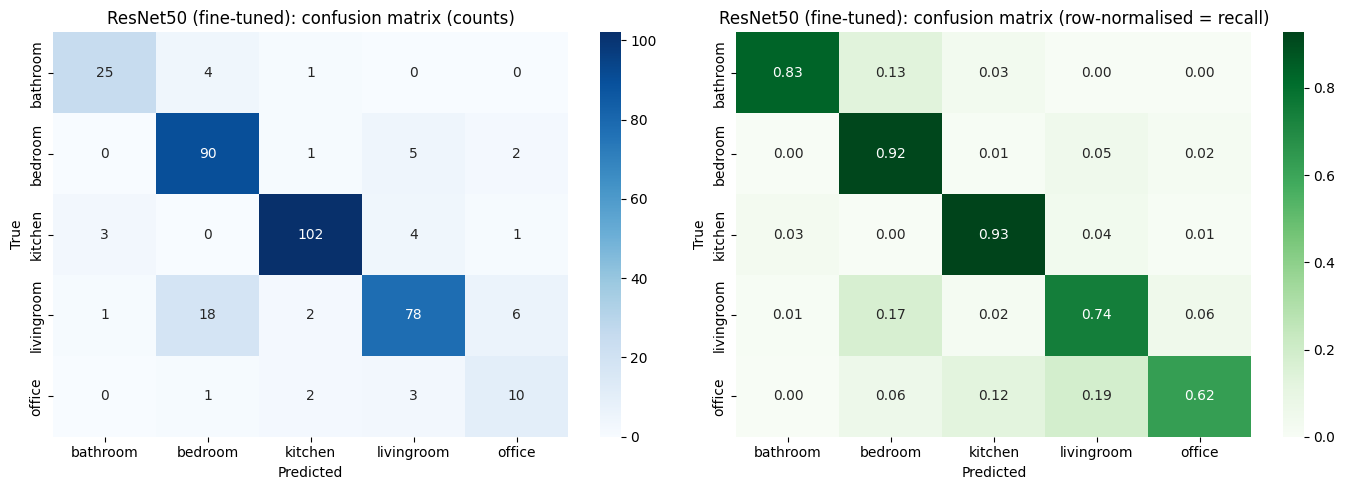

In [21]:
combined = {k: hist_p1.history[k] + hist_p2.history[k] for k in hist_p1.history if k in hist_p2.history}
plot_history(combined, 'ResNet50 (frozen + fine-tuning)', boundary=len(hist_p1.history['accuracy']))
res_resnet = evaluate_model(resnet, 'ResNet50 (fine-tuned)')

## 13. CNN vs ResNet50 Comparison

,Model,Test accuracy,Macro-F1,Parameters,Inference (ms/img),Training time (s)
0,Custom CNN,0.4930,0.4542,1208677,2.0495,609.1814
1,ResNet50 (fine-tuned),0.8496,0.8015,23597957,4.1707,332.5673


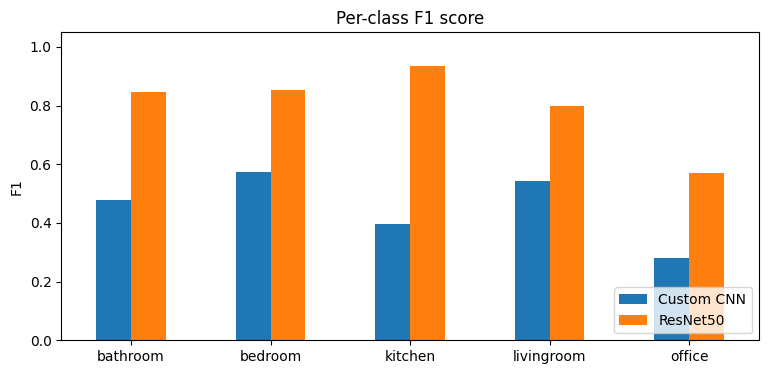

,Custom CNN,ResNet50
bathroom,0.4789,0.8475
bedroom,0.5729,0.8531
kitchen,0.3977,0.9358
livingroom,0.5424,0.8000
office,0.2791,0.5714


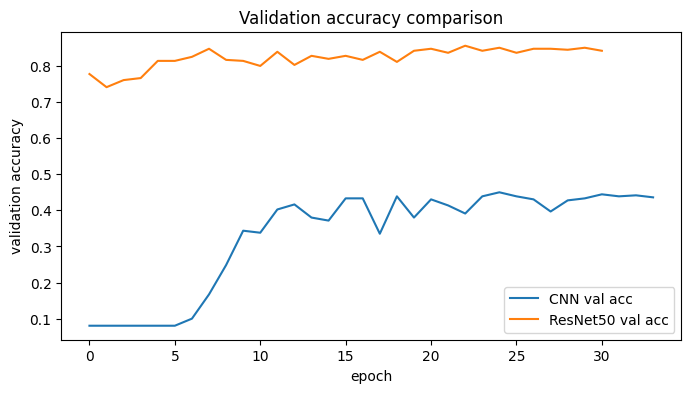

In [22]:
cmp = pd.DataFrame([{
    'Model': r['name'], 'Test accuracy': r['accuracy'], 'Macro-F1': r['macro_f1'],
    'Parameters': r['params'], 'Inference (ms/img)': r['ms_per_image']} for r in (res_cnn, res_resnet)])
cmp['Training time (s)'] = [cnn_train_time, resnet_train_time]
display(cmp.round(4))

f1_df = pd.DataFrame({'Custom CNN': res_cnn['f1'], 'ResNet50': res_resnet['f1']}, index=CLASSES)
f1_df.plot(kind='bar', figsize=(9, 4), rot=0)
plt.title('Per-class F1 score'); plt.ylabel('F1'); plt.ylim(0, 1.05); plt.legend(loc='lower right')
plt.show()
display(f1_df.round(4))

# Side-by-side learning curves (validation accuracy)
plt.figure(figsize=(8, 4))
plt.plot(hist_cnn.history['val_accuracy'], label='CNN val acc')
plt.plot(combined['val_accuracy'], label='ResNet50 val acc')
plt.xlabel('epoch'); plt.ylabel('validation accuracy'); plt.title('Validation accuracy comparison')
plt.legend(); plt.show()

## 14. Error Analysis

### 14.1 Misclassified images

Model used for error analysis: ResNet50 (fine-tuned)
Misclassified: 54 / 359


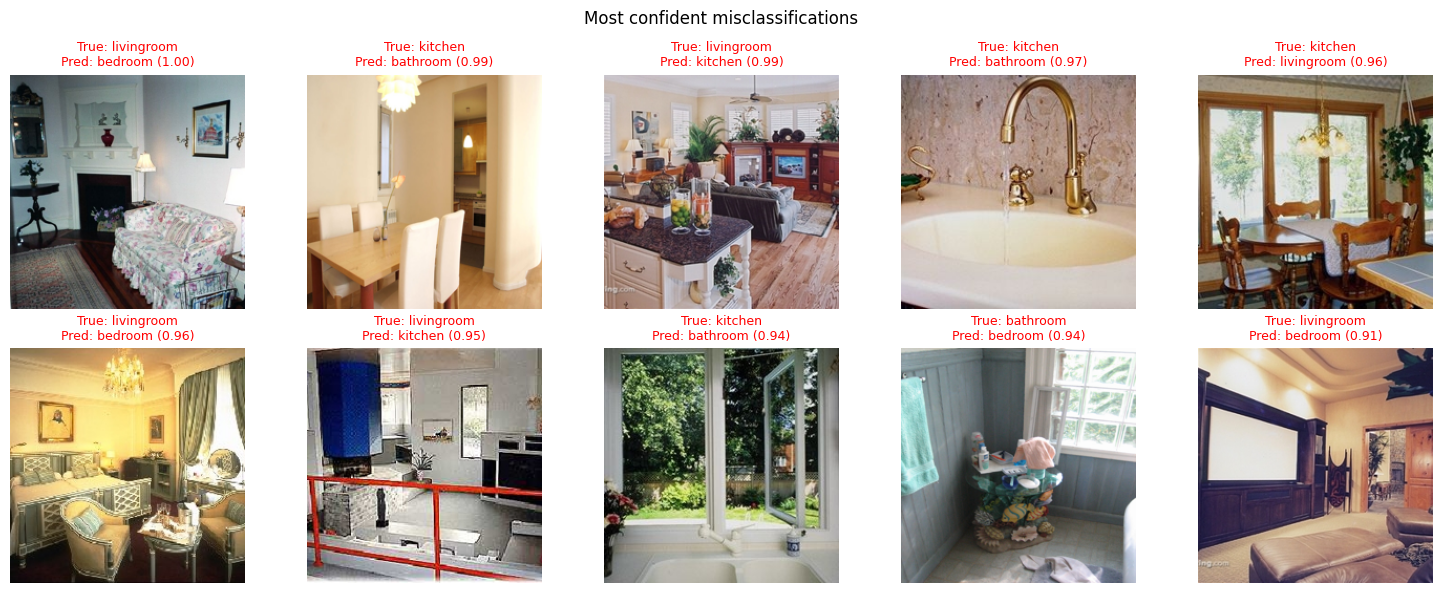

In [23]:
best = res_resnet if res_resnet['accuracy'] >= res_cnn['accuracy'] else res_cnn
print('Model used for error analysis:', best['name'])
wrong = np.where(best['y_pred'] != y_test)[0]
print(f'Misclassified: {len(wrong)} / {len(y_test)}')

conf = best['probs'][wrong].max(1)
order = wrong[np.argsort(-conf)][:10]
plt.figure(figsize=(15, 6))
for k, i in enumerate(order):
    plt.subplot(2, 5, k + 1)
    plt.imshow(Image.open(test_paths[i]).convert('RGB').resize(IMG_SIZE)); plt.axis('off')
    plt.title(f'True: {CLASSES[y_test[i]]}\nPred: {CLASSES[best["y_pred"][i]]} ({best["probs"][i].max():.2f})',
              fontsize=9, color='red')
plt.suptitle('Most confident misclassifications'); plt.tight_layout(); plt.show()

### 14.2 Difficult room pairs

,CNN errors,ResNet50 errors
Pair,,
bedroom <-> livingroom,36,23
livingroom <-> office,13,9
kitchen <-> livingroom,54,6
bathroom <-> bedroom,19,4
bathroom <-> kitchen,12,4
bedroom <-> office,2,3


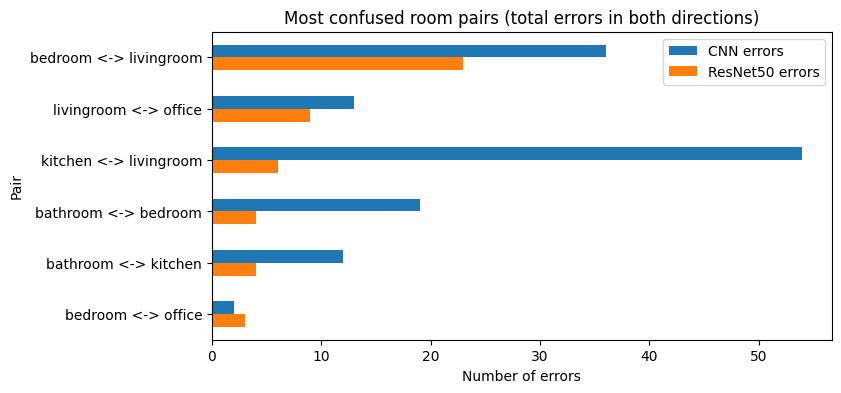

In [24]:
def confusing_pairs(res, name):
    cm = confusion_matrix(y_test, res['y_pred'])
    pairs = []
    for i in range(NUM_CLASSES):
        for j in range(i + 1, NUM_CLASSES):
            pairs.append((f'{CLASSES[i]} <-> {CLASSES[j]}', cm[i, j] + cm[j, i]))
    s = pd.DataFrame(pairs, columns=['Pair', name]).set_index('Pair')
    return s

pairs_df = confusing_pairs(res_cnn, 'CNN errors').join(confusing_pairs(res_resnet, 'ResNet50 errors'))
pairs_df = pairs_df.sort_values('ResNet50 errors', ascending=False)
display(pairs_df.head(6))
pairs_df.head(6).plot(kind='barh', figsize=(8, 4)).invert_yaxis()
plt.title('Most confused room pairs (total errors in both directions)'); plt.xlabel('Number of errors')
plt.show()

### 14.3 Grad-CAM: what does ResNet50 look at?
Grad-CAM highlights the regions that drove a prediction. It checks that the model uses meaningful objects (bed, sink, desk) rather than background artefacts, which matters for trust in an automated home system.

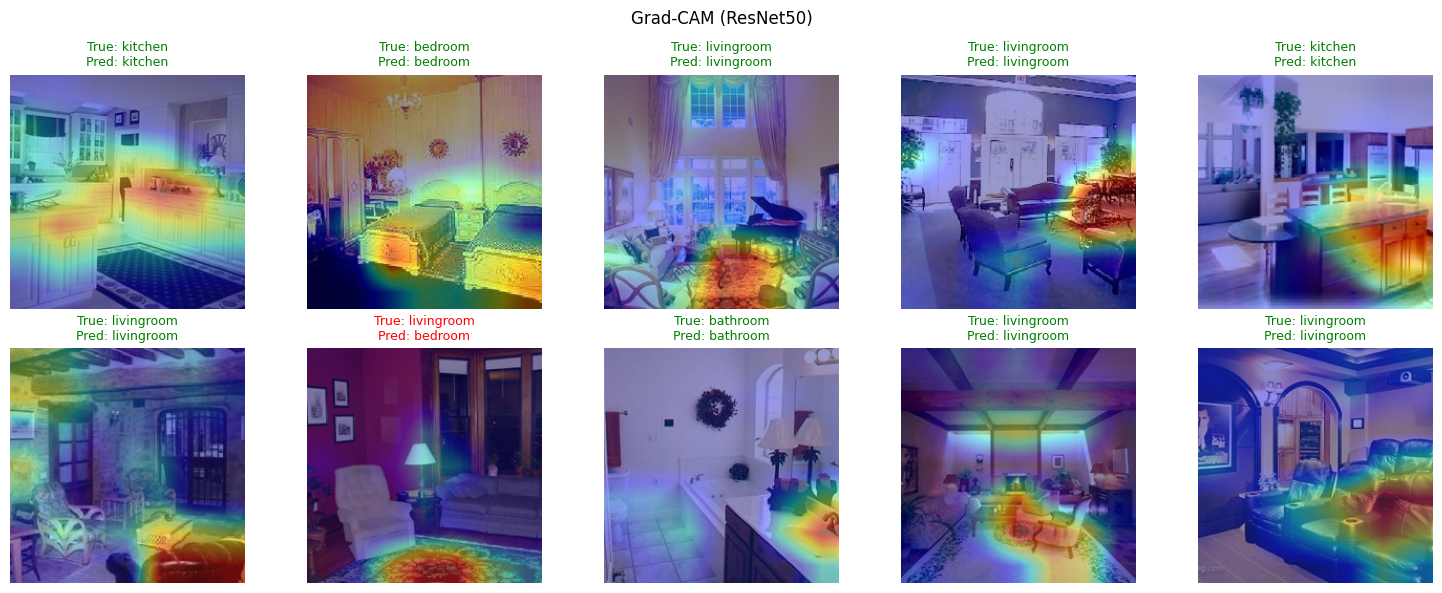

In [25]:
def grad_cam(img_uint8, model):
    base = get_base(model)
    x = preprocess_input(tf.cast(img_uint8[None], tf.float32))
    with tf.GradientTape() as tape:
        conv = base(x, training=False)                      # last conv feature map (7x7x2048)
        pooled = tf.reduce_mean(conv, axis=[1, 2])
        preds = model.get_layer('predictions')(pooled)
        idx = tf.argmax(preds[0])
        score = preds[:, idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=[1, 2])
    cam = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), int(idx)

rng = np.random.RandomState(SEED)
chosen = rng.choice(len(test_paths), 10, replace=False)
plt.figure(figsize=(15, 6))
for k, i in enumerate(chosen):
    img = np.array(Image.open(test_paths[i]).convert('RGB').resize(IMG_SIZE)).astype('uint8')
    cam, pred = grad_cam(img, resnet)
    cam_r = np.array(Image.fromarray((cam * 255).astype('uint8')).resize(IMG_SIZE, Image.BILINEAR)) / 255.
    plt.subplot(2, 5, k + 1)
    plt.imshow(img); plt.imshow(cam_r, cmap='jet', alpha=0.4); plt.axis('off')
    ok = pred == y_test[i]
    plt.title(f'True: {CLASSES[y_test[i]]}\nPred: {CLASSES[pred]}', fontsize=9, color='green' if ok else 'red')
plt.suptitle('Grad-CAM (ResNet50)'); plt.tight_layout(); plt.show()

## 15. Test Individual Images
This simulates how HomeVision would use the model: classify one image, report confidence, and map the result to a smart-home action. Predictions below a confidence threshold are treated as *uncertain*, and the system keeps its current settings instead of acting on a doubtful result.

Val acc | CNN: 0.4385 | ResNet50: 0.8547 -> best model: ResNet50 (fine-tuned)
TRUE CLASS: bathroom


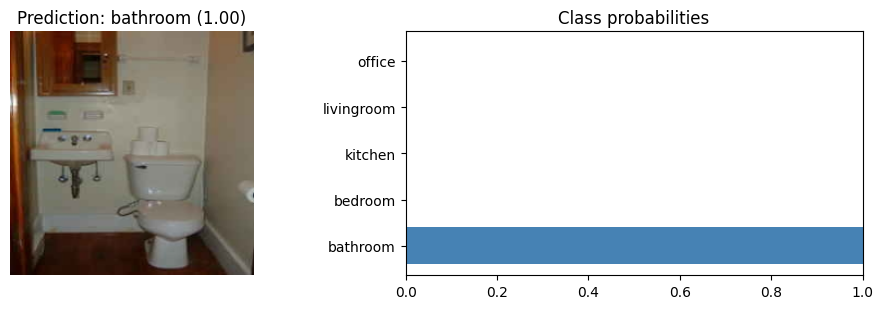

Suggested automation: Humidity-triggered ventilation, bright task lighting, motion-based off timer
TRUE CLASS: bedroom


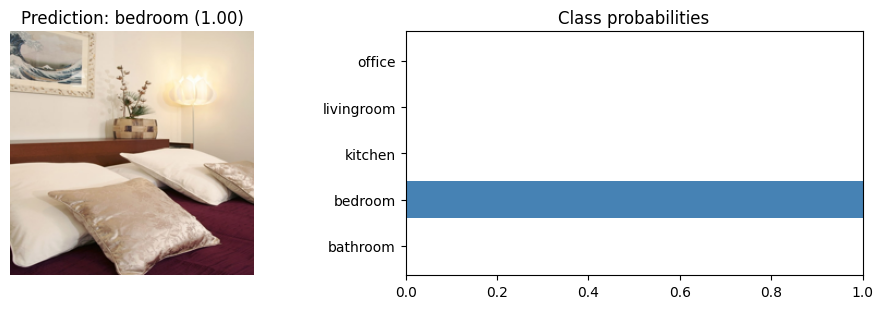

Suggested automation: Warm dimmable lighting, comfort temperature, night-time energy saving
TRUE CLASS: kitchen


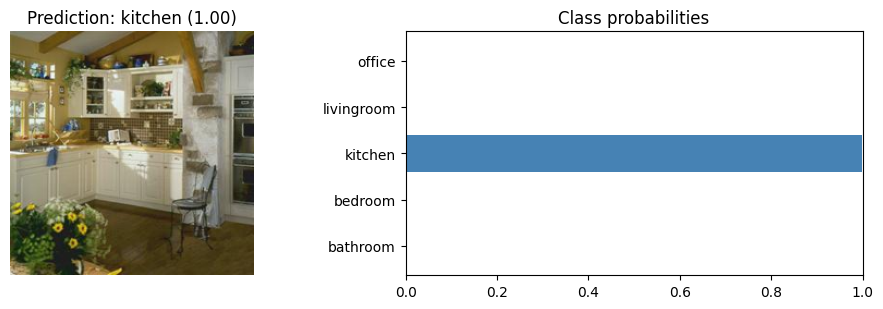

Suggested automation: Bright lighting, extractor fan on during cooking, appliance safety checks
TRUE CLASS: livingroom


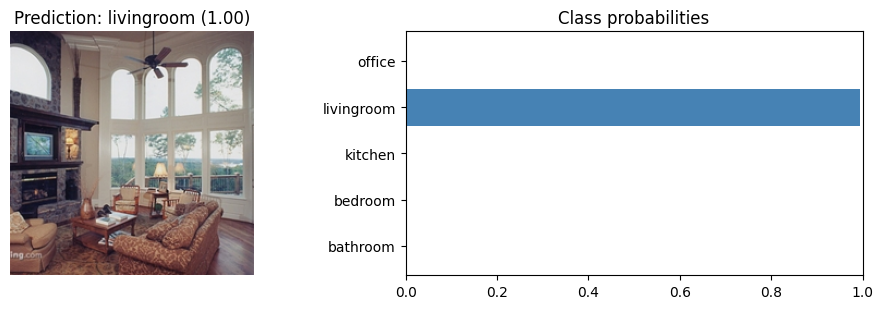

Suggested automation: Ambient lighting scenes, multimedia presets, occupancy-based HVAC
TRUE CLASS: office


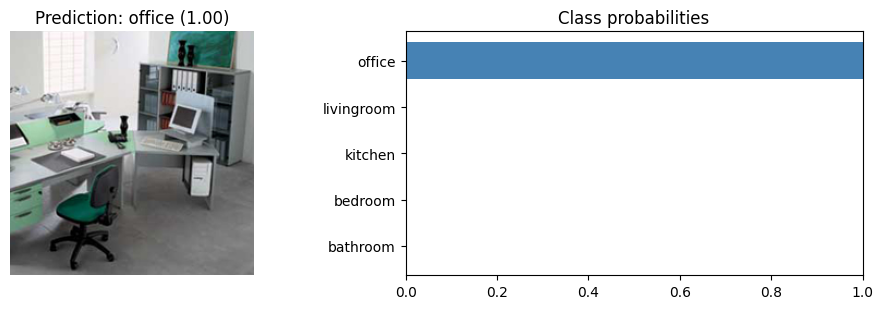

Suggested automation: Cool daylight lighting, focus-friendly temperature, power-down when empty


In [26]:
# Choose the better model using VALIDATION accuracy (keeps the test set untouched for selection)
val_acc_cnn    = cnn.evaluate(val_ds, verbose=0)[1]
val_acc_resnet = resnet.evaluate(val_ds, verbose=0)[1]
best_model, best_name = (resnet, 'ResNet50 (fine-tuned)') if val_acc_resnet >= val_acc_cnn else (cnn, 'Custom CNN')
print(f'Val acc | CNN: {val_acc_cnn:.4f} | ResNet50: {val_acc_resnet:.4f} -> best model: {best_name}')

CONF_THRESHOLD = 0.60
AUTOMATION = {
    'bathroom':   'Humidity-triggered ventilation, bright task lighting, motion-based off timer',
    'bedroom':    'Warm dimmable lighting, comfort temperature, night-time energy saving',
    'kitchen':    'Bright lighting, extractor fan on during cooking, appliance safety checks',
    'livingroom': 'Ambient lighting scenes, multimedia presets, occupancy-based HVAC',
    'office':     'Cool daylight lighting, focus-friendly temperature, power-down when empty',
}

def predict_image(path, model=None, show=True):
    model = model or best_model
    img = Image.open(path).convert('RGB').resize(IMG_SIZE)
    arr = np.array(img).astype('uint8')[None]
    probs = model.predict(arr, verbose=0)[0]
    k = int(probs.argmax()); conf = float(probs[k])
    decision = CLASSES[k] if conf >= CONF_THRESHOLD else 'uncertain'
    action = AUTOMATION.get(decision, 'Confidence too low: keep current settings')
    if show:
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
        ax[0].imshow(img); ax[0].axis('off'); ax[0].set_title(f'Prediction: {decision} ({conf:.2f})')
        ax[1].barh(CLASSES, probs, color='steelblue'); ax[1].set_xlim(0, 1); ax[1].set_title('Class probabilities')
        plt.tight_layout(); plt.show()
        print('Suggested automation:', action)
    return decision, conf

# One random test image from each class
for c in CLASSES:
    p = test_df[test_df.label == c].sample(1, random_state=SEED)['path'].iloc[0]
    print('TRUE CLASS:', c)
    predict_image(p)

Saving bedroom.jpg to bedroom.jpg


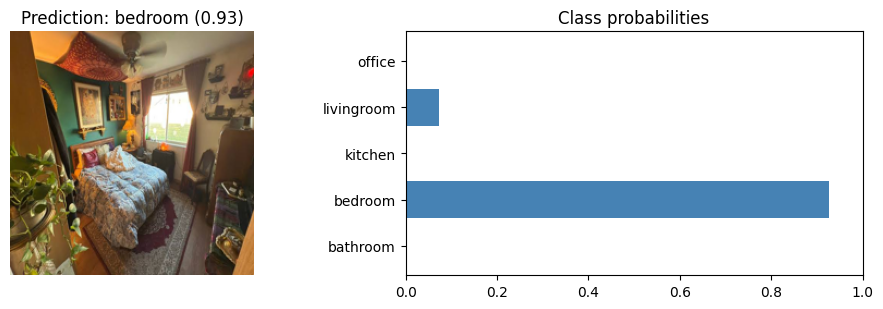

Suggested automation: Warm dimmable lighting, comfort temperature, night-time energy saving


In [27]:
# Upload your own photo (e.g. a room in your home) and classify it
from google.colab import files
uploaded = files.upload()
for fname in uploaded:
    predict_image(fname)

## 16. Save Best Model

In [28]:
os.makedirs('/content/saved_models', exist_ok=True)
cnn.save('/content/saved_models/custom_cnn.keras')
resnet.save('/content/saved_models/resnet50_finetuned.keras')
best_model.save('/content/saved_models/best_model.keras')
with open('/content/saved_models/class_names.json', 'w') as f:
    json.dump(CLASSES, f)
print('Best model saved:', best_name)
print(os.listdir('/content/saved_models'))

Best model saved: ResNet50 (fine-tuned)
['custom_cnn.keras', 'best_model.keras', 'resnet50_finetuned.keras', 'class_names.json']


## 17. Critical Discussion

### 17.1 Limitations

* Only 5 of 67 classes were selected, and some classes have fewer images, particularly **office and bathroom**, so class-level test estimates can be noisy.

* A single stratified train/validation/test split was used. Cross-validation or repeated splits could provide more reliable performance estimates and confidence intervals.

* Hyperparameter tuning used a relatively small grid because of computational limitations.

* Predictions are based on a single still image. A real smart-home system could improve reliability by combining video frames, time information, and additional sensor data.

### 17.2 Overfitting

* The custom CNN shows a noticeable difference between training and validation performance, indicating some degree of overfitting. This is expected because the dataset is relatively small and the CNN is trained from scratch. The validation performance does not improve consistently with training, while the training performance continues to improve.

* Several mitigation techniques were used, including data augmentation, dropout, L2 regularisation, batch normalisation, global average pooling, early stopping, and class weighting.

* ResNet50 also has a risk of overfitting during fine-tuning. Therefore, only the later layers were intended to be unfrozen, a low learning rate was used, and Batch Normalisation layers were kept frozen.

### 17.3 Dataset Limitations

* **Class imbalance:** The classes contain different numbers of images, meaning minority classes have less training evidence and may achieve lower recall.

* **Domain gap:** The MIT Indoor Scenes dataset contains images from web and photo collections rather than Sri Lankan apartments or real CCTV-style wide-angle cameras. Therefore, real-world performance may be lower because of differences in lighting, decoration, architecture, and camera position.

* **Label ambiguity:** Open-plan homes and multi-purpose rooms may not fit clearly into a single category, such as a living room combined with a kitchen or a home office located inside a bedroom.

* **Possible near-duplicates:** Although exact duplicates were removed, visually similar or near-duplicate images may still exist across the dataset splits.

### 17.4 Privacy

* Indoor cameras can capture highly sensitive information about people and their homes.

* Recommended safeguards include on-device inference, avoiding storage or upload of raw images, obtaining explicit user consent, encrypting data, and using non-visual sensors where cameras are inappropriate.

* Bathroom and bedroom recognition highlights an important privacy concern because these are private spaces where cameras may be unacceptable. A privacy-preserving approach could process images locally and immediately discard the original frames after classification.

### 17.5 Smart-Home Implications

* **Benefits:** Indoor scene recognition could support automatic lighting and HVAC control, energy-saving automation, occupancy-aware services, and context-aware recommendations.

* **Risks:** An incorrect prediction could trigger an inappropriate automation action. The confidence threshold and safe fallback used in the project can reduce this risk. Safety-critical functions should not depend on the classifier alone.

* **Deployment:** The ResNet50 model provides substantially better classification performance than the custom CNN but requires more computational resources. Edge deployment could therefore benefit from techniques such as quantisation, pruning, or a lighter architecture such as MobileNetV3 or EfficientNet-Lite.

* **Fairness and robustness:** The system should be tested under different lighting conditions, home styles, camera heights, and environments before real-world deployment.

### 17.6 Future Improvements

Future work could include collecting a larger and more diverse dataset, particularly images from local homes and real smart-home environments. Additional improvements could include testing EfficientNet or other lightweight architectures, test-time augmentation, model ensembling, k-fold cross-validation, and introducing an **"unknown room"** class so that the system can avoid making an unreliable prediction when an image does not clearly belong to one of the five trained categories.


## 18. Conclusion

This project developed an indoor scene recognition system for five smart-home categories: **bathroom, bedroom, kitchen, livingroom, and office**. The dataset was preprocessed using image validation, duplicate removal, resizing, normalization, augmentation, and class balancing.

Two models were evaluated: a custom CNN and a ResNet50 transfer-learning model. The CNN achieved **45.13% test accuracy**, while ResNet50 achieved **86.63%**, showing a **41.50 percentage-point improvement** through transfer learning. ResNet50 performed particularly well on the kitchen class, while **office** was the most challenging class with an F1-score of **0.645**.

The results demonstrate that ResNet50 is effective for indoor scene recognition and could support smart-home applications such as context-aware automation and room-specific services. However, further testing with larger and more diverse real-world datasets is required. Privacy, secure data handling, and on-device processing should also be considered before practical deployment.
